# MonsoonWatch — explainable next-day heavy-rainfall warning for Sri Lanka

**Machine Learning Assignment · MSc in AI**

This notebook walks through the whole project in the order of the assignment guideline:

1. Problem definition and dataset
2. Selection of a new algorithm — the Explainable Boosting Machine (EBM)
3. Model training and evaluation
4. Explainability and interpretation
5. Critical discussion
6. Front-end integration (Streamlit app, deployed on Azure)

Every step calls the scripts in `src/`, so the notebook, the scripts and the report always give the same numbers.

**How to run:** `pip install -r requirements-dev.txt`, then *Run All* (about 5 minutes on a laptop). Python 3.12 or newer. All random seeds are fixed at 42.

In [1]:
import sys, io, json, contextlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import config, data_prep, train, evaluate, explain, export_app_assets
import plot_style as ps
ps.apply()
%matplotlib inline
pd.set_option("display.max_columns", 30, "display.width", 160)

def quiet(fn, *args, **kwargs):
    # run a pipeline step without its console printout (results are shown as tables below)
    with contextlib.redirect_stdout(io.StringIO()):
        return fn(*args, **kwargs)

def show(fig_name, width=850):
    display(Image(filename=str(config.FIG_DIR / fig_name), width=width))

## 1. Problem definition and dataset

### 1.1 Problem and relevance
Heavy rain triggers most of Sri Lanka's floods and landslides (Cyclone Ditwah, November 2025, left more than 450 people dead). The task is to predict, at the end of each day, whether a location will receive **≥ 20 mm of rain the next day** — the WMO ETCCDI definition of a *very heavy precipitation day* (index R20mm). Because people must act on a warning, the model's reasoning has to be visible, so explainability is central.

### 1.2 Data source
Public **Sri Lanka Weather Dataset** (author *rasulmah*, Kaggle, licence **CC0**), compiled from the **Open-Meteo historical weather API**. Values are weather-model (reanalysis) estimates for grid cells, not rain-gauge readings. The dataset contains no personal or sensitive data.

In [2]:
raw = data_prep.load_raw()
print(f"{len(raw):,} rows × {raw.shape[1]} columns · {raw['city'].nunique()} cities · "
      f"{raw['time'].min().date()} to {raw['time'].max().date()}")
raw[["time", "city", "precipitation_sum", "precipitation_hours", "temperature_2m_max",
     "temperature_2m_min", "windspeed_10m_max", "winddirection_10m_dominant", "weathercode"]].head()

147,480 rows × 19 columns · 30 cities · 2010-01-01 to 2023-06-17


,time,city,precipitation_sum,precipitation_hours,temperature_2m_max,temperature_2m_min,windspeed_10m_max,winddirection_10m_dominant,weathercode
0,2010-01-01,Athurugiriya,0.0,0.0,29.9,22.5,17.9,20,1
1,2010-01-02,Athurugiriya,0.0,0.0,30.0,23.3,17.7,20,1
2,2010-01-03,Athurugiriya,0.2,1.0,29.5,22.9,16.6,16,51
3,2010-01-04,Athurugiriya,0.0,0.0,28.7,21.7,18.2,4,3
4,2010-01-05,Athurugiriya,0.0,0.0,28.0,21.1,17.4,3,1


### 1.3 Data quality checks
`data_prep.check_quality()` looks for missing values, impossible values and gaps in each city's daily sequence. (The columns `snowfall_sum` — always 0 — `rain_sum` — identical to `precipitation_sum` — `country`, `sunrise` and `sunset` were already dropped by `load_raw()`.)

In [3]:
q = data_prep.check_quality(raw)
pd.Series(q, name="result").to_frame()

,result
rows,147480
cities,30
date_min,2010-01-01
date_max,2023-06-17
missing_values,0
negative_rain,0
tmin_above_tmax,0
date_gaps,0


**Key finding — duplicated cities.** Neighbouring cities fall in the same grid cell of the source weather model, so their daily rainfall is *identical*. Keeping all of them would count every Western Province storm up to seven times. The cell below groups cities with exactly the same 4,916-day rainfall series.

In [4]:
deduped, merged = data_prep.deduplicate_grid_cells(raw)
groups = pd.DataFrame([{"kept city": k, "identical rainfall series": ", ".join(v), "cities in cell": len(v) + 1}
                       for k, v in merged.items()])
display(groups)
print(f"Distinct rainfall series: {deduped['city'].nunique()} of {raw['city'].nunique()} cities "
      f"→ {len(deduped):,} rows kept")

,kept city,identical rainfall series,cities in cell
0,Gampaha,"Athurugiriya, Kolonnawa, Mabole, Negombo, Oruw...",7
1,Colombo,"Bentota, Kalutara, Kesbewa, Maharagama, Moratu...",7
2,Galle,"Matara, Weligama",3
3,Kurunegala,Pothuhera,2


Distinct rainfall series: 15 of 30 cities → 73,740 rows kept


### 1.4 Exploratory analysis
How rare is heavy rain, when does it happen, and where?

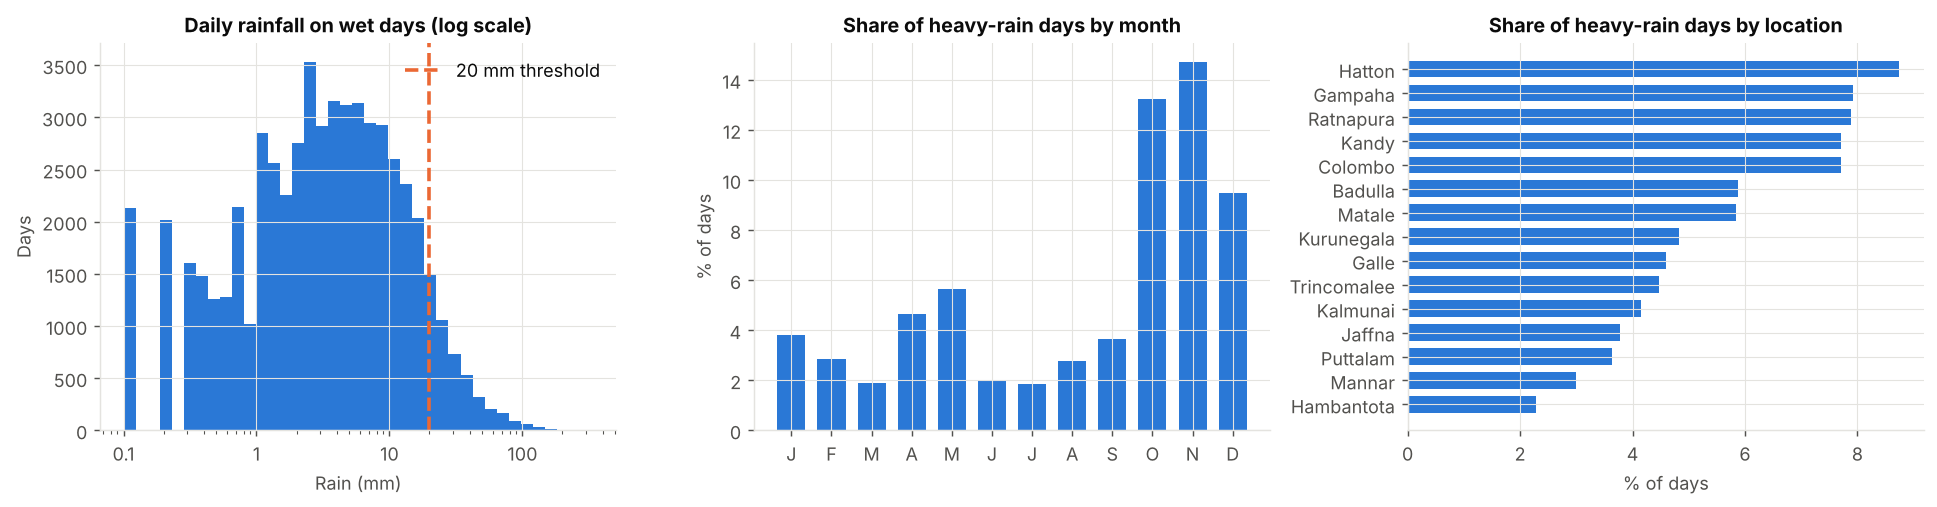

Heavy-rain days overall: 5.5% · wettest month: November (14.7 %) · driest: July (1.9 %)
Most frequent: Hatton, Gampaha, Ratnapura · least frequent: Hambantota, Mannar, Puttalam


In [5]:
d = deduped.copy()
d["heavy"] = d["precipitation_sum"] >= config.HEAVY_RAIN_MM
months = "J F M A M J J A S O N D".split()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
r = d["precipitation_sum"]
ax[0].hist(r[r >= 0.1], bins=np.logspace(-1, np.log10(r.max()), 40), color=ps.SERIES[0])
ax[0].set_xscale("log")
ax[0].axvline(20, color=ps.SERIES[1], ls="--", label="20 mm threshold")
ax[0].set_xticks([0.1, 1, 10, 100]); ax[0].set_xticklabels(["0.1", "1", "10", "100"])
ax[0].set(title="Daily rainfall on wet days (log scale)", xlabel="Rain (mm)", ylabel="Days")
ax[0].legend()

by_month = d.groupby(d["time"].dt.month)["heavy"].mean() * 100
ax[1].bar(range(1, 13), by_month.values, color=ps.SERIES[0], width=0.7)
ax[1].set(title="Share of heavy-rain days by month", ylabel="% of days")
ax[1].set_xticks(range(1, 13)); ax[1].set_xticklabels(months)

by_city = (d.groupby("city")["heavy"].mean() * 100).sort_values()
ax[2].barh(by_city.index, by_city.values, color=ps.SERIES[0], height=0.7)
ax[2].set(title="Share of heavy-rain days by location", xlabel="% of days")
plt.tight_layout(); plt.show()

import calendar
name = lambda i: calendar.month_name[i]
driest = [name(i) for i in by_month.index[by_month == by_month.min()]]
print(f"Heavy-rain days overall: {d['heavy'].mean():.1%} · wettest month: {name(by_month.idxmax())} "
      f"({by_month.max():.1f} %) · driest: {' and '.join(driest)} ({by_month.min():.1f} %)")
print(f"Most frequent: {', '.join(by_city.index[::-1][:3])} · least frequent: {', '.join(by_city.index[:3])}")

Heavy rain is **rare (about 5–6 % of days)**, so accuracy alone would be misleading. It peaks in **October–November** (second inter-monsoon), is most frequent in Hatton in the hill country and in the wet zone (Ratnapura, Gampaha, Kandy, Colombo), and least frequent in the dry south-east and north-west (Hambantota, Mannar, Puttalam).

### 1.5 Features, target and time-based split
`data_prep.main()` builds 23 features per location-day using only information available by the end of that day, and the target `heavy_rain_tomorrow` (1 if the next day has ≥ 20 mm). Rolling and lagged features are computed within each location in date order. Each location's first 13 days (no 14-day history) and last day (no tomorrow) are dropped.

In [6]:
quiet(data_prep.main)
summary = json.loads((config.PROCESSED_DIR / "data_summary.json").read_text())
train_df = pd.read_csv(config.PROCESSED_DIR / "train.csv", dtype={"weathercode": str})
feat = pd.DataFrame({"feature": config.FEATURES, "description": [config.LABELS[f] for f in config.FEATURES],
                     "type": ["categorical" if f in config.CATEGORICAL else "numeric" for f in config.FEATURES]})
feat["train median"] = [train_df[f].median() if f not in config.CATEGORICAL else "–" for f in config.FEATURES]
display(feat)
print(f"Modelling rows: {summary['modelling_rows']:,}")

,feature,description,type,train median
0,rain_today,Rain today (mm),numeric,1.8
1,rain_hours_today,Hours of rain today,numeric,6.0
2,rain_yesterday,Rain yesterday (mm),numeric,1.8
3,rain_3d,"Rain, last 3 days (mm)",numeric,7.5
4,rain_7d,"Rain, last 7 days (mm)",numeric,21.8
5,rain_14d,"Rain, last 14 days (mm)",numeric,49.8
6,wet_days_7d,Wet days in last 7 (>=1 mm),numeric,5.0
7,tmax,Max temperature (°C),numeric,29.2
8,tmin,Min temperature (°C),numeric,24.0
9,temp_range,Daily temperature range (°C),numeric,5.3


Modelling rows: 73,530


In [7]:
split = pd.DataFrame(summary["split"]).T
split["heavy_rain_rate"] = (split["heavy_rain_rate"].astype(float) * 100).round(1).astype(str) + " %"
split

,rows,from,to,heavy_rain_rate
train,54585,2010-01-14,2019-12-31,5.6 %
valid,10965,2020-01-01,2021-12-31,5.2 %
test,7980,2022-01-01,2023-06-16,5.3 %


The split is **chronological** — train 2010–2019, validation 2020–2021, test 2022–mid-2023 — because consecutive days are strongly correlated and a random split would leak tomorrow's weather into training. The heavy-rain rate is stable across the three periods.

**Preprocessing.** No missing values needed imputing. The EBM bins continuous features itself and handles the weather code as a nominal feature, so it needs no scaling or encoding. The baselines use standard scaling (logistic regression) and one-hot encoding of the weather code inside scikit-learn pipelines fitted on training data only.

## 2. Selection of a new algorithm: the Explainable Boosting Machine

The EBM (InterpretML; Lou et al. 2012, 2013; Nori et al. 2019) was not covered in lectures and is not a deep-learning model. It is a **generalised additive model with pairwise interactions (GA²M)**:

$$g\big(P(y=1\mid x)\big) = \beta_0 + \sum_j f_j(x_j) + \sum_{(i,j)\in\mathcal{I}} f_{ij}(x_i, x_j)$$

Each $f_j$ is a *shape function* learned by **cyclic gradient boosting**: in each round the algorithm visits one feature at a time and fits a tiny tree on that feature only, with a small learning rate. Afterwards the top pairwise interactions (found with the FAST algorithm) are boosted on the residuals. The whole procedure is bagged several times, and the trees for each feature are collapsed into a lookup table.

| Model | Form | Non-linear? | Interactions | Explanation |
|---|---|---|---|---|
| Logistic regression | one weight per feature | no | only if added by hand | coefficients |
| Decision tree | one tree of splits | step-wise | all, implicit | readable only when shallow |
| k-NN | vote of nearest examples | yes | implicit | hard |
| Random forest / boosting (XGBoost, LightGBM, CatBoost) | hundreds of trees on many features | yes | all orders, implicit | needs post-hoc SHAP / PDP |
| **EBM** | one curve per feature + a few pairwise surfaces, summed | yes, any shape | small, explicit set | **exact**: every prediction is a visible sum |

**Why EBM:** accuracy close to tree ensembles on tabular data, explanations that are exact rather than approximated, non-linear weather effects (season, wind direction) captured automatically, and a model a meteorologist can audit feature by feature.

## 3. Model training and evaluation

### 3.1 Hyperparameter search
The grid below (12 combinations) was run by `python src/train.py`: each EBM was fitted on 2010–2019 and scored by **PR-AUC on the 2020–2021 validation years**. Fixed settings: 256 bins, early stopping after 100 rounds without improvement on an internal 15 % hold-out, minimum 4 samples per leaf, 2 bags during the search and 8 for the final model.

In [8]:
pd.read_csv(config.RESULTS_DIR / "ebm_hyperparameter_search.csv")

,interactions,learning_rate,max_leaves,valid_pr_auc,valid_roc_auc,fit_seconds
0,20,0.02,2,0.2849,0.8583,11.9
1,20,0.05,3,0.2838,0.8581,5.1
2,20,0.02,3,0.2822,0.8584,5.0
3,20,0.05,2,0.2809,0.8585,6.3
4,10,0.05,2,0.2806,0.8600,5.4
5,10,0.02,2,0.2802,0.8596,12.3
6,10,0.02,3,0.2802,0.8586,5.4
7,10,0.05,3,0.2801,0.8589,4.1
8,0,0.02,2,0.2734,0.8590,14.6
9,0,0.05,2,0.2731,0.8596,5.8


The number of pairwise interactions mattered most; learning rate and tree size changed PR-AUC by less than 0.005. The best setting — **20 interactions, learning rate 0.02, 2 leaves** — is reused below (`quick=True` skips repeating the search).

### 3.2 Train the final EBM and three baselines
Baselines (covered in lectures): logistic regression, random forest (300 trees) and LightGBM (400 trees). For every model the **decision threshold is chosen on the validation years** to maximise F1 for the heavy-rain class, because a 50 % threshold would almost never fire on a 5 % event.

In [9]:
quiet(train.main, quick=True)
meta = json.loads((config.MODEL_DIR / "model_meta.json").read_text())
print("EBM settings:", meta["ebm_params"])
pd.DataFrame(meta["models"]).T[["threshold", "valid_f1", "valid_pr_auc", "valid_roc_auc", "fit_seconds"]].round(3)

EBM settings: {'interactions': 20, 'learning_rate': 0.02, 'max_leaves': 2}


,threshold,valid_f1,valid_pr_auc,valid_roc_auc,fit_seconds
EBM (proposed),0.156,0.356,0.287,0.858,41.9
Logistic Regression,0.141,0.348,0.262,0.859,0.2
Random Forest,0.158,0.356,0.284,0.856,12.0
LightGBM,0.152,0.354,0.276,0.861,1.6


### 3.3 Results on the untouched test set (Jan 2022 – Jun 2023)
Metrics: **PR-AUC** (ranking quality for the rare class; a random model scores the base rate, about 0.053), **ROC-AUC**, **precision / recall / F1** at the chosen threshold, and the **Brier score** (quality of the probabilities). 95 % confidence intervals come from 1,000 bootstrap resamples of test days.

In [10]:
quiet(evaluate.main)
comp = pd.read_csv(config.RESULTS_DIR / "model_comparison.csv")
display(comp.set_index("Model"))
print((config.RESULTS_DIR / "significance.txt").read_text())

,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,Balanced acc.,Brier,Threshold,ROC-AUC 95% CI,PR-AUC 95% CI
Model,,,,,,,,,,,
EBM (proposed),0.8525,0.2354,0.3450,0.2664,0.4894,0.9015,0.7070,0.0446,0.1557,0.836-0.868,0.205-0.275
Logistic Regression,0.8361,0.2040,0.3150,0.2233,0.5343,0.8768,0.7151,0.0461,0.1415,0.818-0.854,0.178-0.236
Random Forest,0.8438,0.2037,0.3037,0.2307,0.4444,0.8920,0.6807,0.0455,0.1579,0.825-0.860,0.177-0.235
LightGBM,0.8432,0.2102,0.2989,0.2423,0.3901,0.9030,0.6609,0.0460,0.1519,0.827-0.861,0.182-0.244
Persistence (heavy today -> heavy tomorrow),NaN,NaN,0.2220,0.2217,0.2222,0.9174,0.5893,NaN,NaN,NaN,NaN
Always 'no heavy rain',NaN,NaN,0.0000,NaN,0.0000,0.9470,0.5000,NaN,NaN,NaN,NaN


PR-AUC gain of EBM over Logistic Regression: 0.032 (95% CI 0.012 to 0.054)
PR-AUC gain of EBM over Random Forest: 0.032 (95% CI 0.017 to 0.049)
PR-AUC gain of EBM over LightGBM: 0.025 (95% CI 0.011 to 0.041)



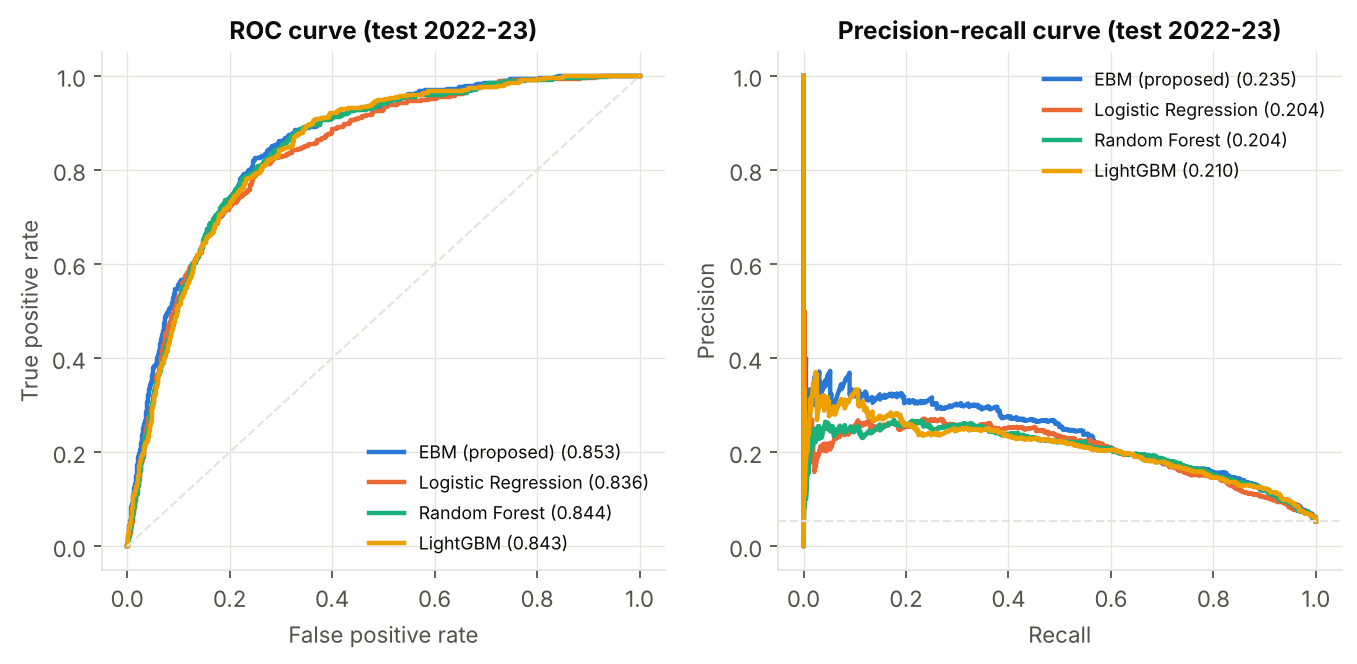

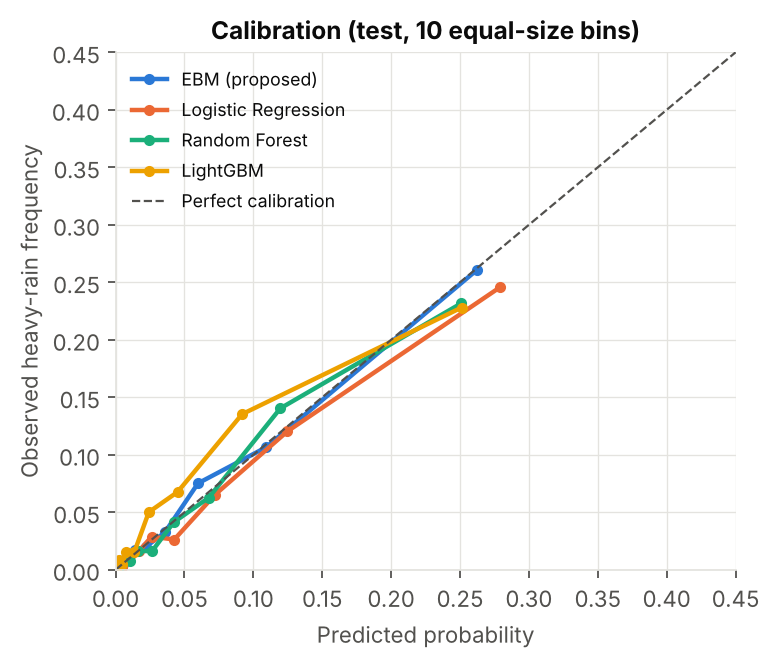

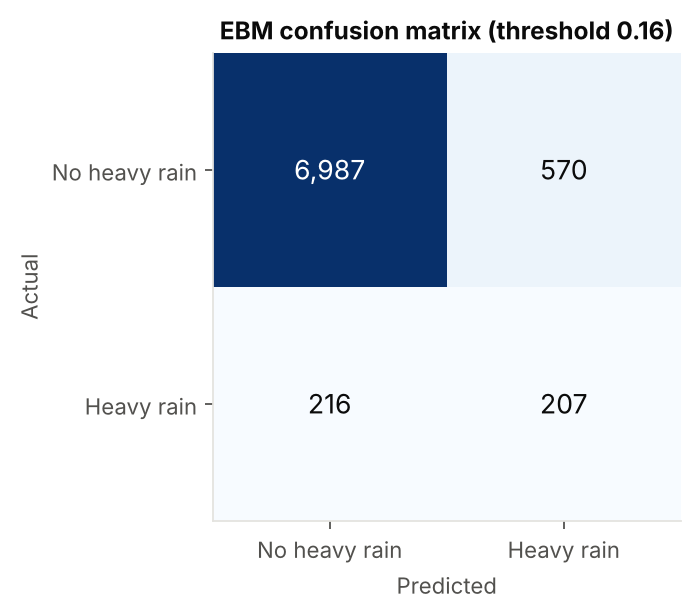

In [11]:
show("roc_pr_curves.png")
show("calibration.png", 420)
show("confusion_matrix.png", 380)

In [12]:
m = json.loads((config.RESULTS_DIR / "metrics.json").read_text())
cm = m["ebm_confusion_matrix"]
print(f"Heavy-rain days in test: {cm['tp'] + cm['fn']} · caught: {cm['tp']} · missed: {cm['fn']} · "
      f"false alarms: {cm['fp']} of {cm['tn'] + cm['fp']:,} ordinary days")
display(pd.read_csv(config.RESULTS_DIR / "ebm_by_season.csv").set_index("season"))

Heavy-rain days in test: 423 · caught: 207 · missed: 216 · false alarms: 570 of 7,557 ordinary days


,days,heavy_days,recall,precision,pr_auc
season,,,,,
Inter-monsoon,2745.0,199.0,0.583,0.273,0.262
NE monsoon (Dec-Feb),2235.0,101.0,0.366,0.234,0.194
SW monsoon (May-Sep),3000.0,123.0,0.439,0.278,0.252


**What the results indicate.** The EBM has the best ROC-AUC (0.853), PR-AUC (0.235), F1 and Brier score; in paired bootstraps its PR-AUC is higher than every baseline's. Its PR-AUC is about 4.4 times a random model's, and its F1 (0.345) is well above the naive persistence rule (0.222). It catches about half of heavy-rain days, and about one warning in four verifies. All models are well calibrated, so the probability shown in the app can be taken at face value. Interpretability cost nothing in accuracy.

## 4. Explainability and interpretation

Four complementary methods (`src/explain.py`):

1. **EBM global importance and shape functions** — exact, built into the model
2. **SHAP** — permutation SHAP on the EBM and TreeSHAP on LightGBM: do two different models rely on the same evidence?
3. **Partial dependence plots** — EBM vs LightGBM
4. **Local explanations** — why the EBM warned, or did not, on specific days

In [13]:
quiet(explain.main)
ex = json.loads((config.RESULTS_DIR / "explanations.json").read_text())
imp = pd.Series(ex["ebm_term_importance"]).head(10)
imp.index = [" × ".join(config.LABELS.get(t.strip(), t) for t in i.split("&")) for i in imp.index]
imp.rename("mean |contribution| (log-odds)").to_frame()

,mean |contribution| (log-odds)
Weather code today,0.6863
Min temperature (°C),0.2564
Rain today (mm),0.2559
Dominant wind direction (°),0.2489
Rain yesterday (mm),0.2468
Hours of rain today,0.2432
Evapotranspiration ET0 (mm),0.2261
Max wind speed (km/h),0.2126
"Rain, last 14 days (mm)",0.2089
"Rain, last 3 days (mm)",0.1848


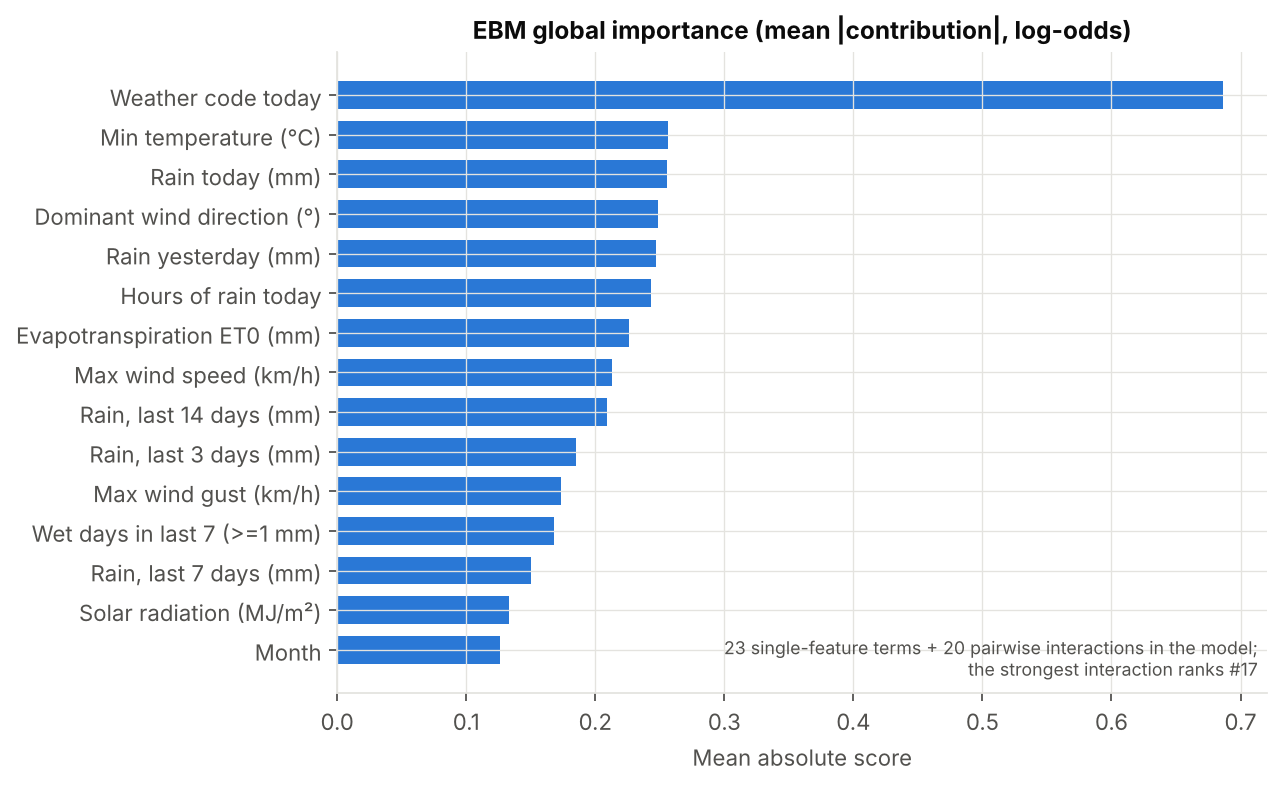

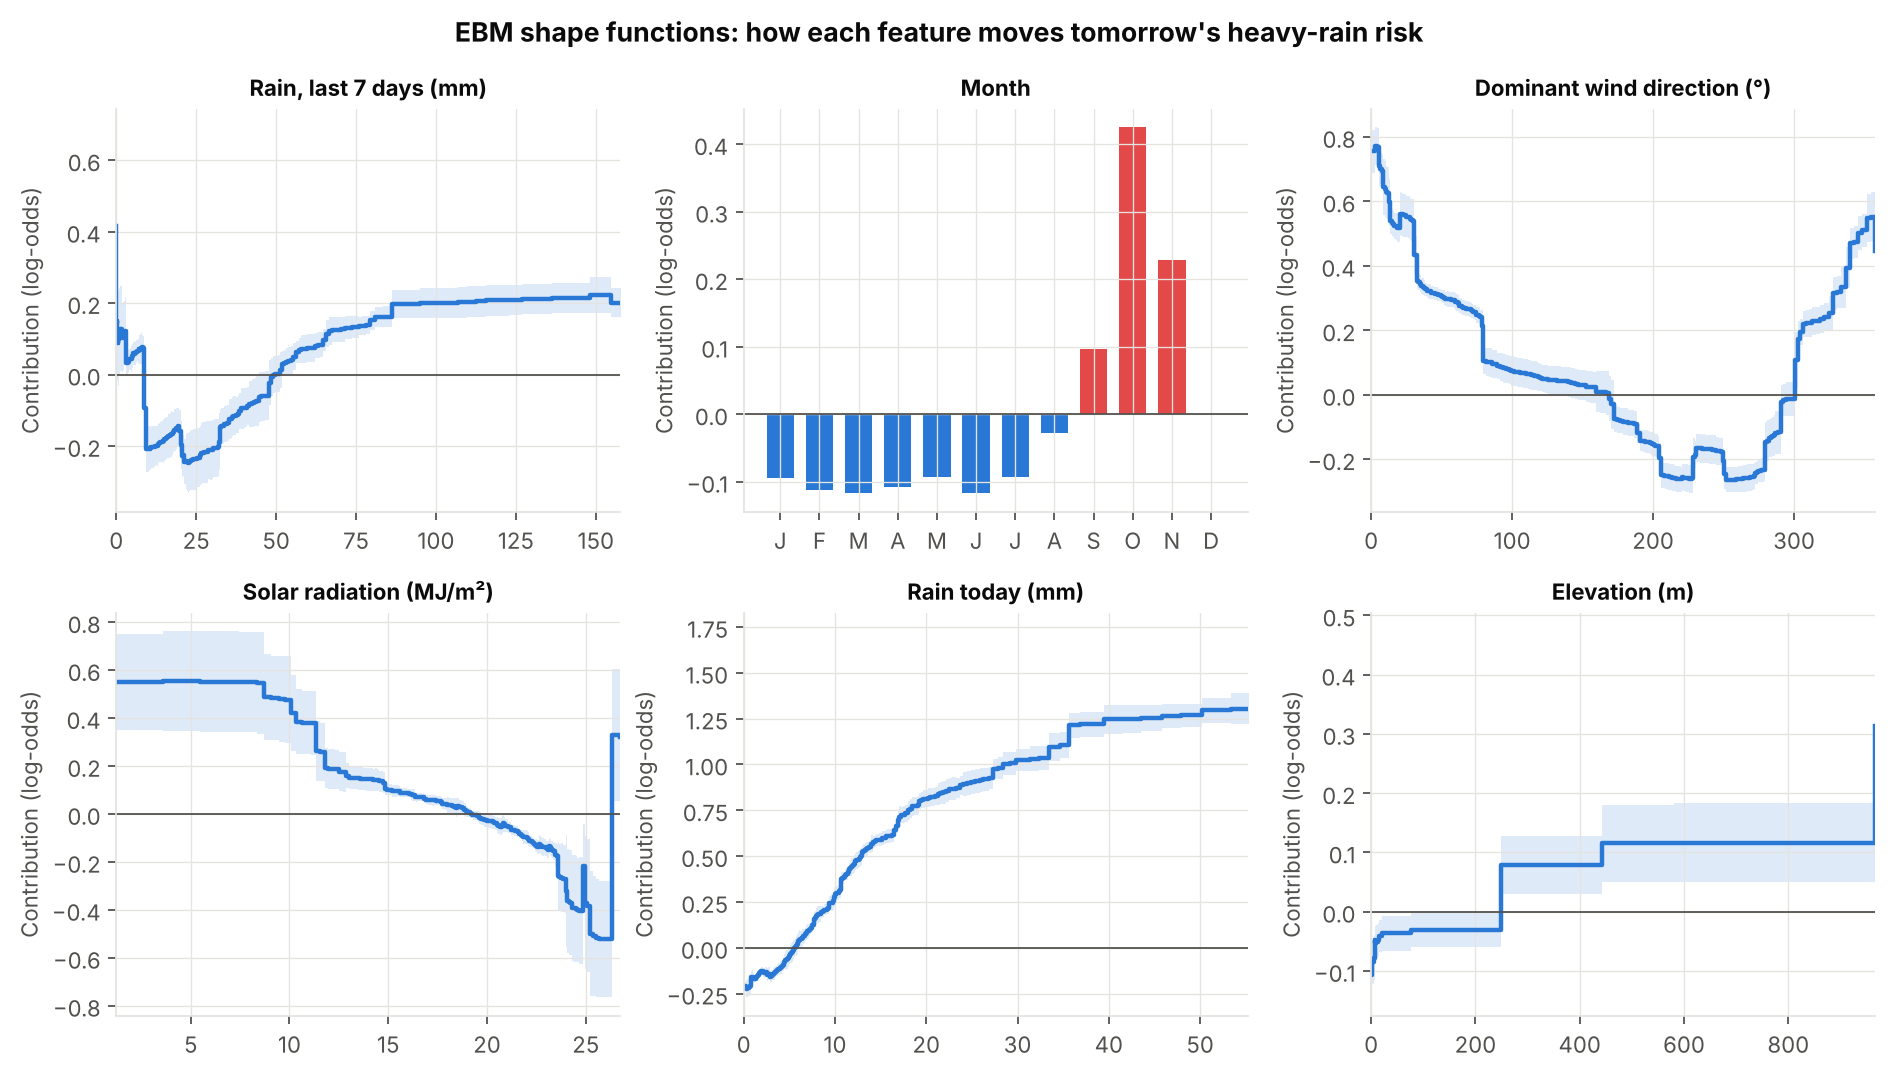

In [14]:
show("ebm_global_importance.png", 700)
show("ebm_shape_functions.png", 950)

**What the model has learned (shape functions):**

| Feature | Learned effect | Agrees with domain knowledge? |
|---|---|---|
| Weather code | clear sky −2.2 … heavy rain +1.0 log-odds | yes — wet spells persist |
| Rain today | rises steadily, flattens above ~50 mm | yes — monotonic and saturating |
| Month | October +0.43, November +0.23; Jan–Jul about −0.1 | yes — second inter-monsoon brings floods and most cyclones |
| Wind direction | northerly/north-easterly up to +0.8; south-westerly about −0.25 | yes for this mix: 9 of 15 locations get their rain from the north-east monsoon |
| Solar radiation | cloudy days +0.5, sunny days −0.3; spike above 26 MJ/m² | mostly — the spike sits on very few days (wide band): an artefact |
| Elevation | hill-country locations +0.1 | yes — orographic lifting |

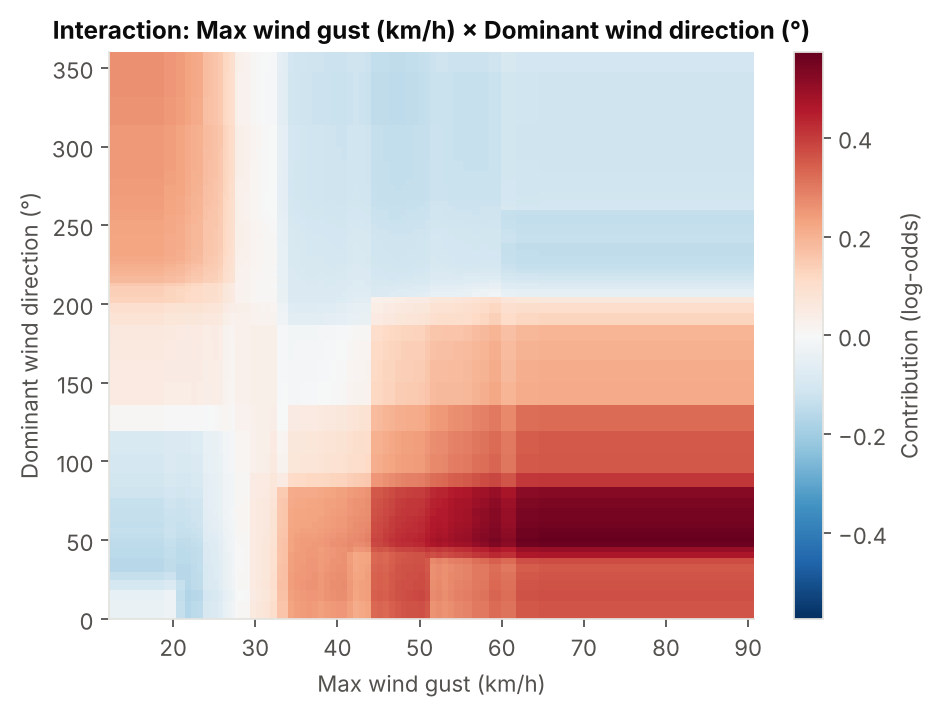

In [15]:
show("ebm_top_interaction.png", 600)

The strongest interaction says **strong gusts from the north-east to east add up to +0.5** on top of the separate effects — the signature of Bay of Bengal depressions and cyclones, which approach from the east.

### 4.2 SHAP and partial dependence: do different models agree?

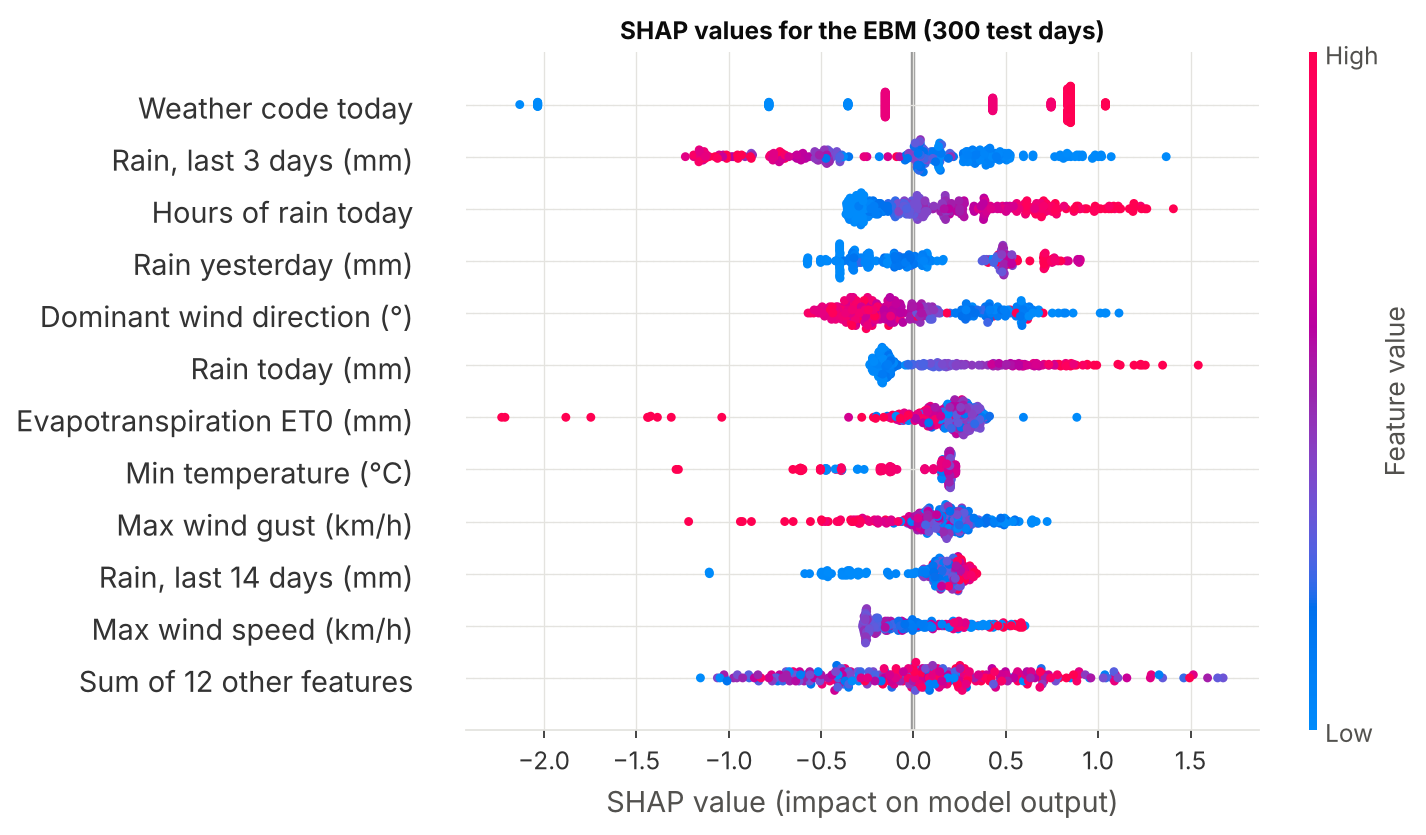

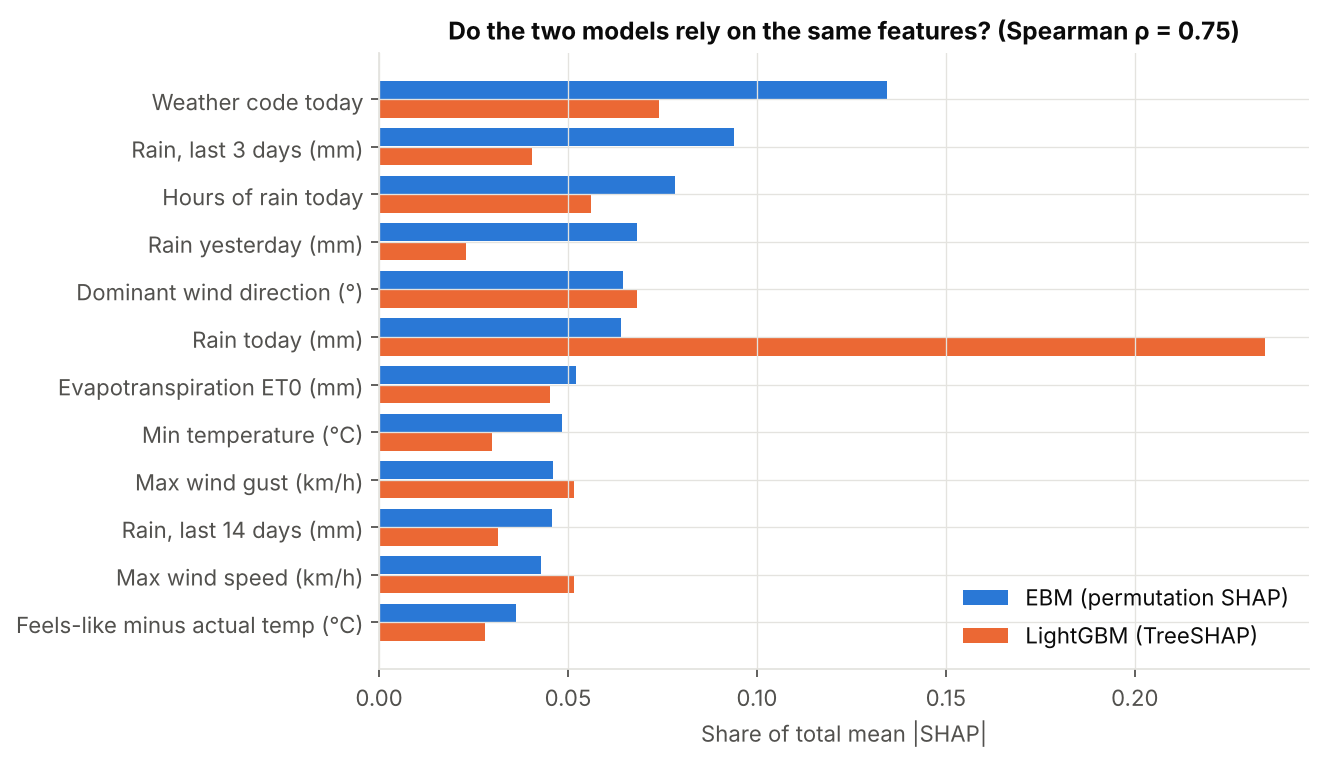

Spearman rank agreement of mean |SHAP|, EBM vs LightGBM: 0.75


In [16]:
show("shap_beeswarm_ebm.png", 800)
show("shap_ebm_vs_lightgbm.png", 750)
print(f"Spearman rank agreement of mean |SHAP|, EBM vs LightGBM: {ex['spearman_rank_agreement']:.2f}")

Both models rely on similar evidence (ρ ≈ 0.75). LightGBM concentrates almost a quarter of its attribution on *rain today*, while the EBM spreads it over weather code, hours of rain and recent totals.

**A warning about post-hoc SHAP.** SHAP gives high 3-day rainfall a strongly negative value, while the EBM's own contribution for the same days is about zero. SHAP's masker swaps one feature at a time, creating *impossible weather* (for example a 3-day total smaller than yesterday's rain). The training data has no such rows, so the model is unconstrained there. The EBM's exact contributions don't have this problem, and the web app forces the rainfall history to stay consistent.

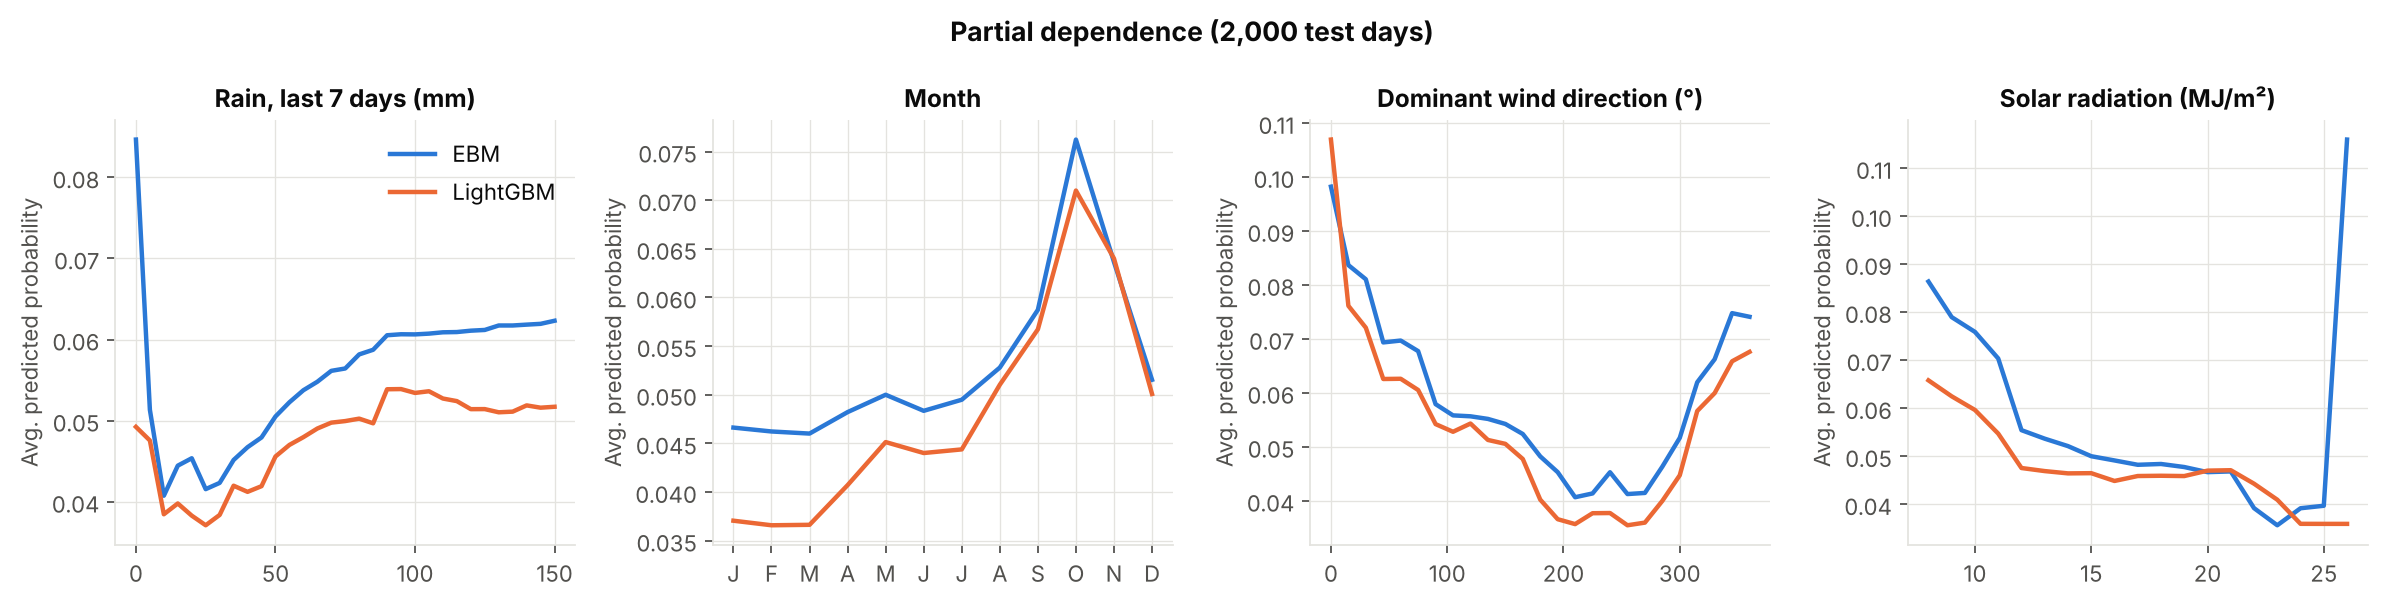

In [17]:
show("pdp_ebm_vs_lightgbm.png", 950)

The two models draw nearly the same partial-dependence curves for month, wind direction and radiation — independent algorithms finding the same pattern is good evidence it is real.

### 4.3 Local explanations: three real days

,city,date,prob,rain_tomorrow_mm
Correct warning (true positive),Mannar,2023-02-01,0.73,22.9
False alarm (false positive),Jaffna,2023-02-02,0.77,7.3
Missed heavy rain (false negative),Mannar,2022-04-09,0.09,107.3


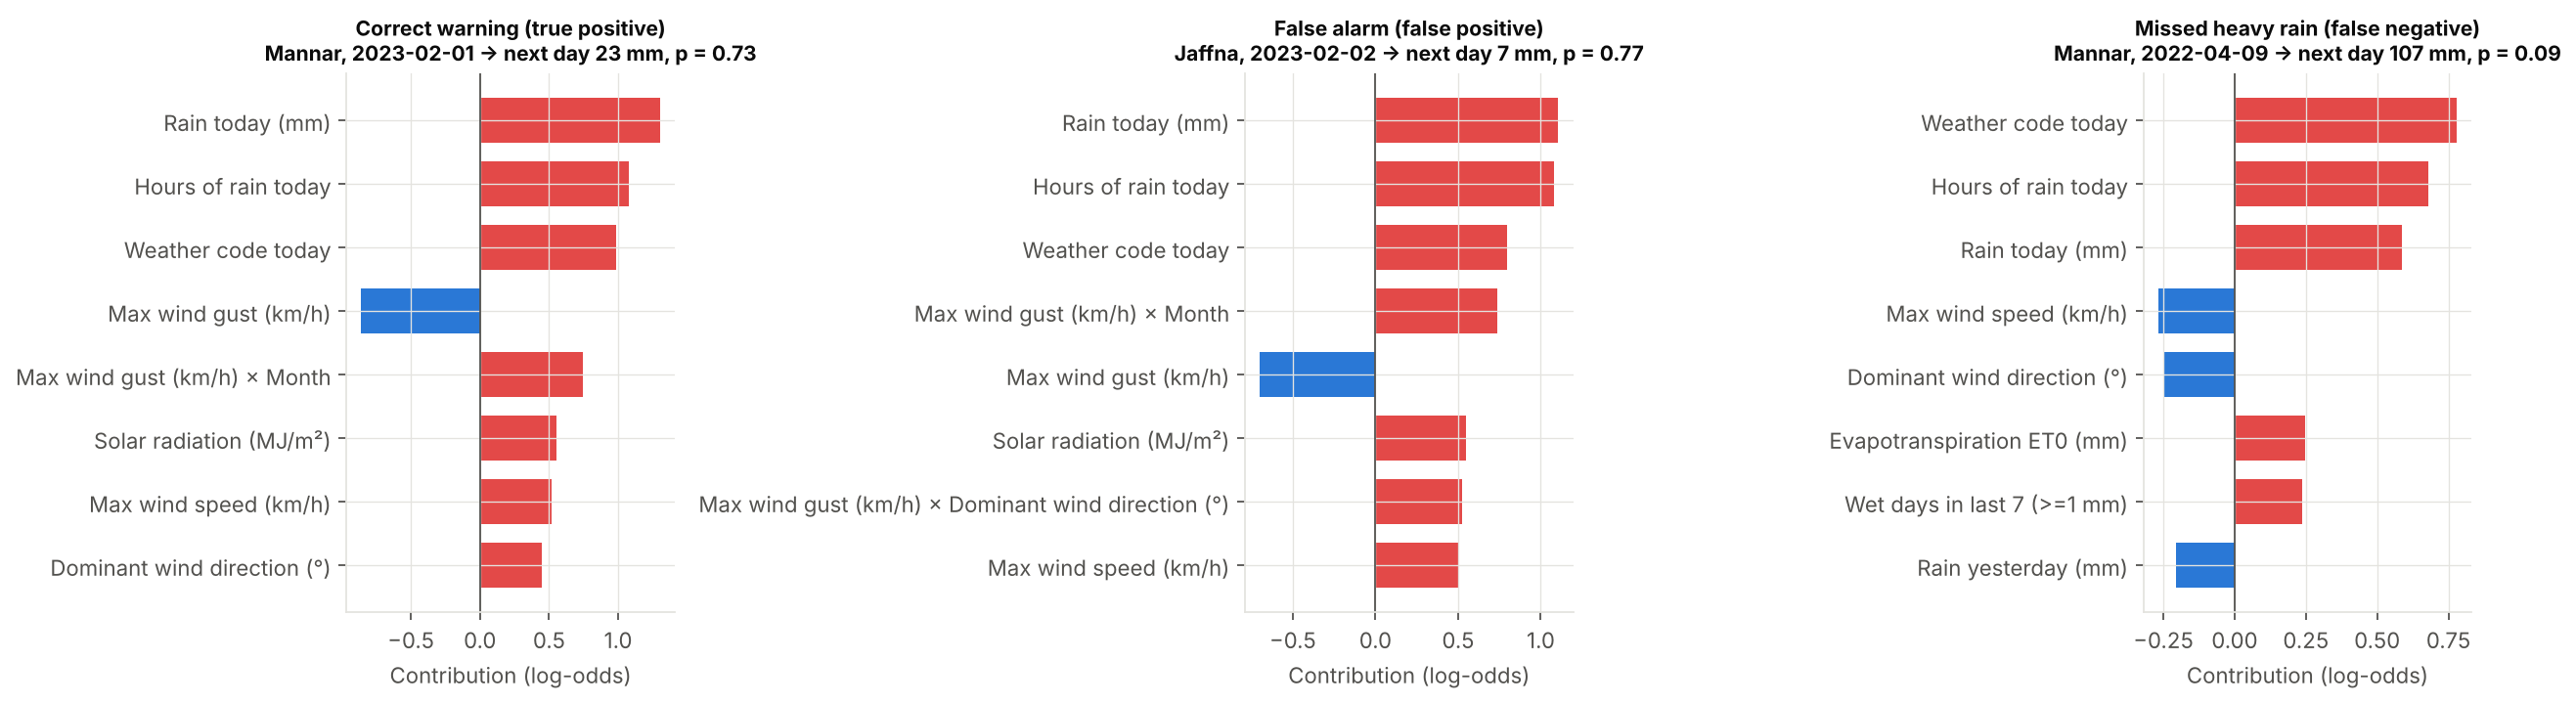

In [18]:
cases = pd.DataFrame(ex["local_cases"]).T[["city", "date", "prob", "rain_tomorrow_mm"]]
cases["prob"] = cases["prob"].astype(float).round(2)
display(cases)
show("local_explanations.png", 950)

- **Correct warning (Mannar, 1 Feb 2023):** heavy rain all day pushed the probability to 0.73; 22.9 mm fell next day.
- **False alarm (Jaffna, 2 Feb 2023):** the same system and reasoning, but it moved on — the model cannot see where a system is heading from one location's daily summary.
- **Missed event (Mannar, 9 Apr 2022):** 107 mm after a moderately wet day — an inter-monsoon convective storm that left no trace in the previous day's data.

## 5. Critical discussion

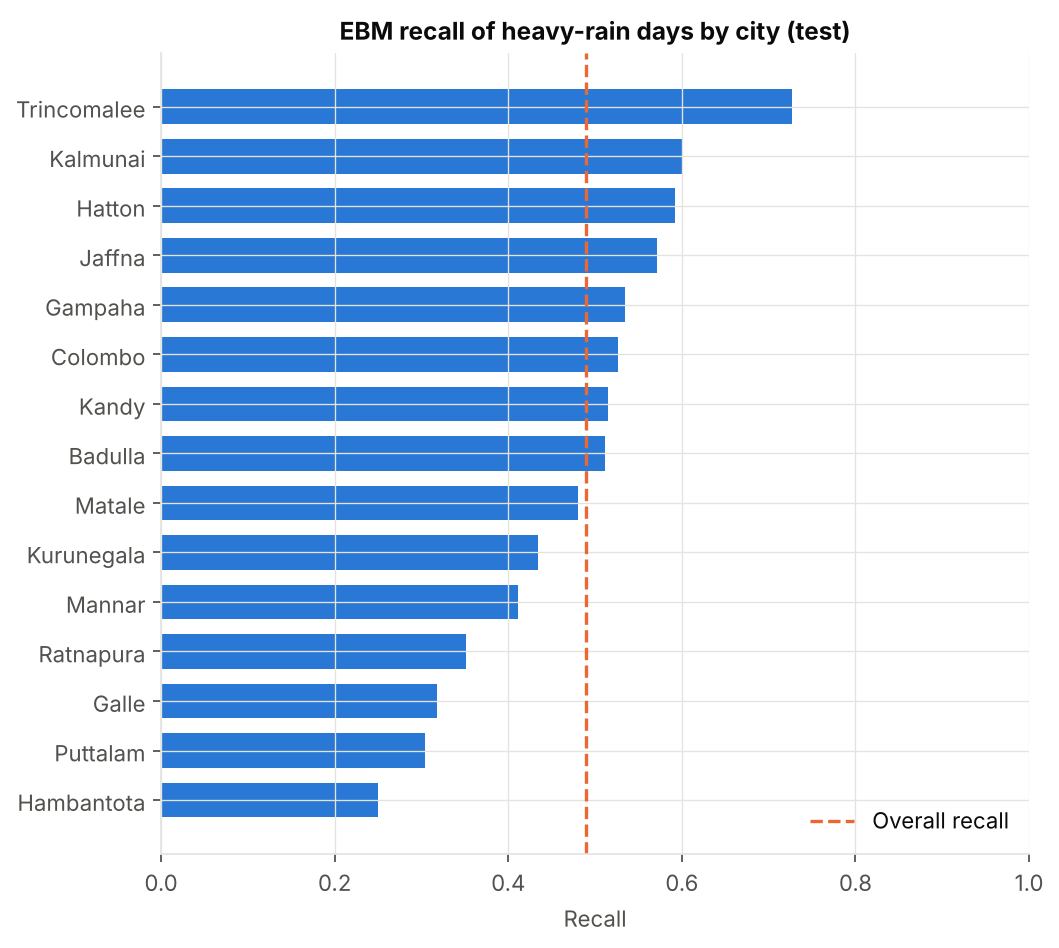

Recall ranges from 25% (Hambantota) to 73% (Trincomalee)


In [19]:
by_city = pd.read_csv(config.RESULTS_DIR / "ebm_by_city.csv").set_index("city").sort_values("recall")
show("recall_by_city.png", 600)
print(f"Recall ranges from {by_city['recall'].min():.0%} ({by_city['recall'].idxmin()}) "
      f"to {by_city['recall'].max():.0%} ({by_city['recall'].idxmax()})")

- **Limitations:** one location's daily summary cannot see approaching weather systems or sudden convective storms; the rainfall features overlap (correlated inputs); training ends in 2019 while the climate is shifting.
- **Data quality:** reanalysis values for grid cells, not gauge observations; half the cities were duplicates; 15 cells do not cover the whole island; the test period holds only 423 heavy-rain days.
- **Bias / unfairness:** recall varies strongly by location — the south (Galle, Hambantota, Ratnapura) and Puttalam are under-served by a single island-wide threshold. Per-region thresholds and per-district reporting would be needed before any real use.
- **Impact and ethics:** missed warnings cost more than false alarms, but too many false alarms erode trust. This is a student prototype, not a replacement for the Department of Meteorology or the Disaster Management Centre; no personal data is collected.

## 6. Front-end integration

`export_app_assets.main()` copies the trained EBM, the city list, the test days and the metrics into `app/assets/`, so the `app/` folder can run on its own. The Streamlit app (`app/app.py`) lets users replay a real day or enter their own conditions, and shows the probability, a risk level and the exact contribution of each feature. It is deployed on **Azure App Service** from the GitHub repository; locally it runs with `streamlit run app/app.py`.

The cell below does what the app does for one real day: load the packaged model, predict, and list the largest contributions.

In [20]:
quiet(export_app_assets.main)
import joblib
app_model = joblib.load(ROOT / "app" / "assets" / "ebm.joblib")
days = pd.read_csv(ROOT / "app" / "assets" / "test_days.csv.gz", dtype={"weathercode": str})
row = days[(days["city"] == "Mannar") & (days["date"] == "2023-02-01")]
p = app_model.predict_proba(row[config.FEATURES])[0, 1]
loc = app_model.explain_local(row[config.FEATURES]).data(0)
contrib = pd.Series(loc["scores"], index=loc["names"])
contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8)
print(f"Mannar, 1 Feb 2023 → P(heavy rain tomorrow) = {p:.0%} · actual next-day rain: "
      f"{row['rain_tomorrow_mm'].iloc[0]:.1f} mm")
contrib.rename("contribution (log-odds)").round(3).to_frame()

Mannar, 1 Feb 2023 → P(heavy rain tomorrow) = 73% · actual next-day rain: 22.9 mm


,contribution (log-odds)
rain_today,1.302
rain_hours_today,1.078
weathercode,0.985
gust_max,-0.858
gust_max & month,0.744
radiation,0.552
wind_max,0.521
wind_dir,0.445


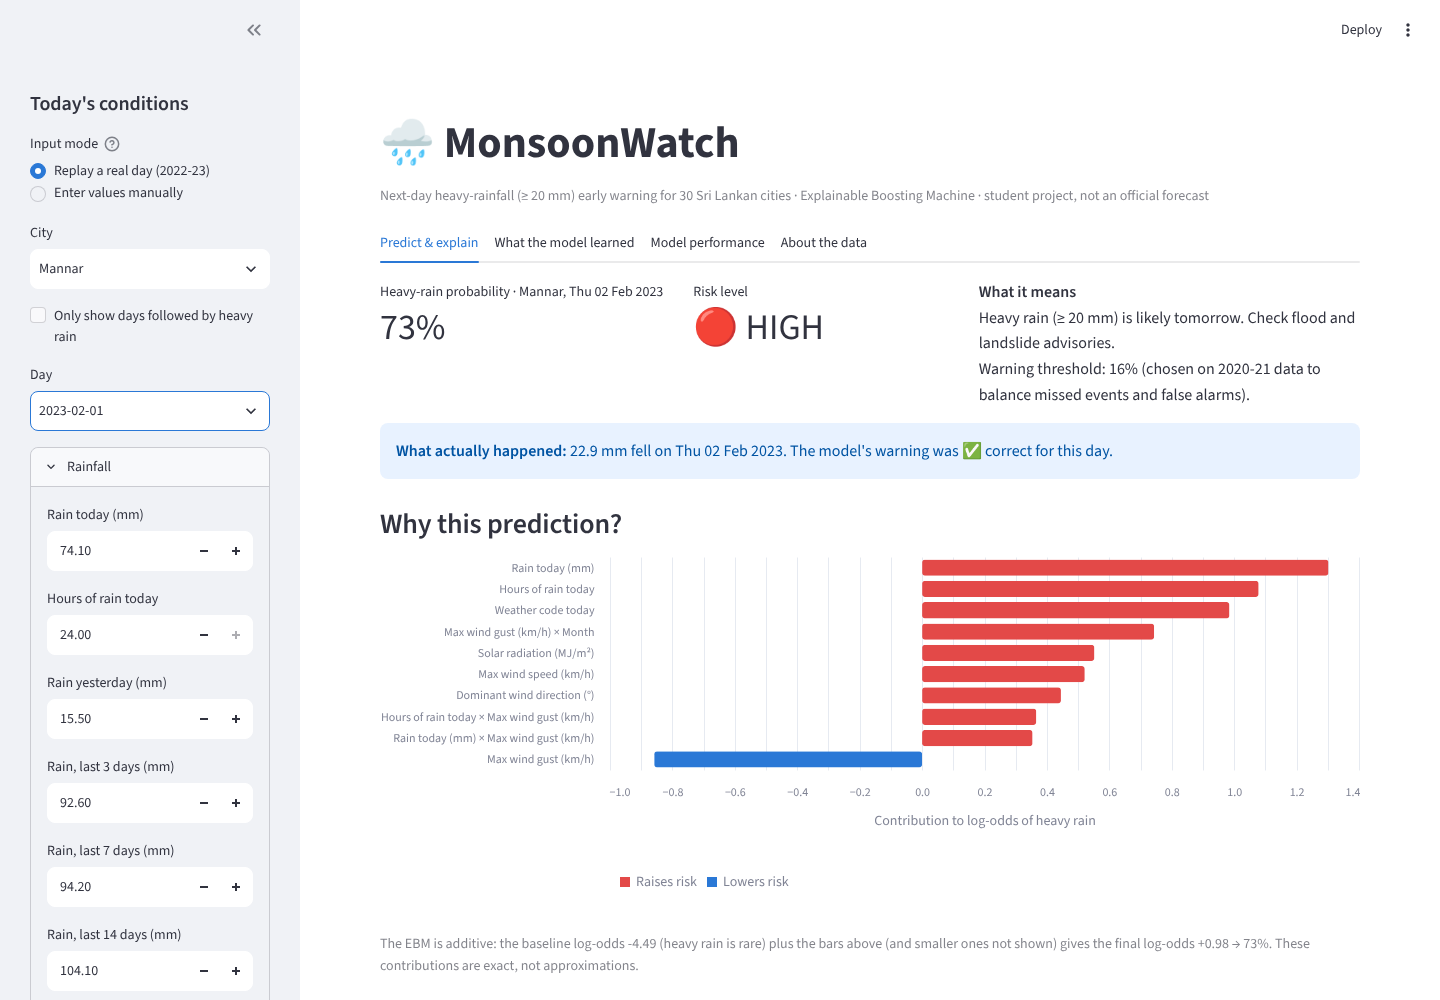

In [21]:
display(Image(filename=str(ROOT / "reports" / "app_screenshots" / "0_predict_mannar_high.png"), width=950))

## Conclusion
An Explainable Boosting Machine trained on 13 years of public Sri Lankan weather data predicts next-day heavy rain with **ROC-AUC 0.853 and PR-AUC 0.235** on unseen 2022–23 data. It is at least as accurate as LightGBM, random forest and logistic regression, while every prediction stays an exact, readable sum of feature contributions. What it learned — persistent wet spells, an October–November peak, and the risk carried by strong north-easterly winds — matches Sri Lankan climatology.